# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [15]:
import random
import random
import statistics
from typing import List
import matplotlib.pyplot as plt

class Card:
    def __init__(self, suit: str, rank: str):
        self.suit = suit
        self.rank = rank
        self.is_plastic = (suit == "Plastic" and rank == "Cut Card")

    def __repr__(self) -> str:
        if self.is_plastic:
            return "[Plastic Cut Card]"
        return f"{self.rank} of {self.suit}"


class Deck:
    SUITS = ["Hearts", "Diamonds", "Clubs", "Spades"]
    RANKS = ["2", "3", "4", "5", "6", "7", "8", "9", "10", "Jack", "Queen", "King", "Ace"]

    def __init__(self, num_decks: int = 1):
        if num_decks < 1:
            raise ValueError("Number of decks must be at least 1.")

        self.num_decks = num_decks
        self.cards: list[Card] = []
        self.needs_shuffle: bool = False

        self.build_and_shuffle()

    def build_and_shuffle(self) -> None:
        self.cards = [
            Card(suit, rank)
            for _ in range(self.num_decks)
            for suit in self.SUITS
            for rank in self.RANKS
        ]

        self.shuffle()
        plastic_card = Card("Plastic", "Cut Card")
        random_index = random.randint(0, len(self.cards))
        self.cards.insert(random_index, plastic_card)

        self.needs_shuffle = False

    def shuffle(self) -> None:
        random.shuffle(self.cards)

    def draw(self) -> Card:

        if self.needs_shuffle or not self.cards:
            print("Reshuffling the deck!")
            self.build_and_shuffle()

        drawn_card = self.cards.pop()

        if drawn_card.is_plastic:
            print(f"Drew {drawn_card}! Deck will be shuffled before the next deal.")
            self.needs_shuffle = True


        return drawn_card

    def __len__(self) -> int:
        return len(self.cards)

if __name__ == "__main__":
    shoe = Deck(num_decks=2)
    print(f"Initial cards in shoe: {len(shoe)}\n")

    for i in range(1, 110):
        card = shoe.draw()
        print(f"Draw {i}: {card}")

        if card.is_plastic:
            print("-> Dealing next card to prove reshuffle triggers:")
            next_card = shoe.draw()
            print(f"Draw {i+1}: {next_card}")
            print(f"Cards remaining in fresh shoe: {len(shoe)}")
            break

Initial cards in shoe: 105

Draw 1: 5 of Clubs
Draw 2: 5 of Spades
Draw 3: Queen of Diamonds
Draw 4: Queen of Hearts
Draw 5: 4 of Diamonds
Draw 6: 3 of Clubs
Draw 7: 10 of Spades
Draw 8: 3 of Clubs
Draw 9: Jack of Diamonds
Draw 10: 4 of Diamonds
Draw 11: 7 of Clubs
Draw 12: 8 of Hearts
Draw 13: 5 of Diamonds
Draw 14: 5 of Diamonds
Draw 15: 9 of Hearts
Draw 16: 7 of Hearts
Draw 17: Ace of Clubs
Draw 18: 7 of Diamonds
Draw 19: 2 of Clubs
Draw 20: 6 of Clubs
Draw 21: 8 of Spades
Draw 22: 4 of Spades
Draw 23: 4 of Spades
Draw 24: 6 of Hearts
Draw 25: Ace of Diamonds
Draw 26: Queen of Diamonds
Draw 27: Queen of Clubs
Draw 28: 3 of Hearts
Draw 29: Queen of Spades
Draw 30: King of Spades
Draw 31: 3 of Spades
Draw 32: Queen of Hearts
Draw 33: 9 of Spades
Draw 34: 9 of Clubs
Draw 35: 5 of Hearts
Draw 36: 2 of Spades
Draw 37: Ace of Hearts
Draw 38: 7 of Hearts
Draw 39: 3 of Spades
Draw 40: Jack of Clubs
Draw 41: 7 of Clubs
Draw 42: Ace of Spades
Draw 43: Jack of Hearts
Draw 44: 9 of Diamonds
Dra

2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [16]:
from typing import List, Optional

class Card:
    def __init__(self, suit: Optional[str], rank: Optional[str], is_plastic: bool = False) -> None:
        self.suit: Optional[str] = suit
        self.rank: Optional[str] = rank
        self.is_plastic: bool = is_plastic

    def get_value(self) -> int:
        pass

    def __repr__(self) -> str:
        pass

class Deck:
    SUITS: List[str] = ["Hearts", "Diamonds", "Clubs", "Spades"]
    RANKS: List[str] = ["2", "3", "4", "5", "6", "7", "8", "9", "10", "Jack", "Queen", "King", "Ace"]

    def __init__(self, num_decks: int = 1) -> None:
        self.num_decks: int = num_decks
        self.cards: List[Card] = []
        self.needs_shuffle: bool = False

    def _build_and_shuffle(self) -> None:
        pass

    def shuffle(self) -> None:
        pass

    def draw(self) -> Card:
        pass

    def __len__(self) -> int:
        pass

class Hand:
    def __init__(self) -> None:
        self.cards: List[Card] = []
        self.bet: float = 0.0
        self.is_standing: bool = False

    def add_card(self, card: Card) -> None:
        pass

    def clear(self) -> None:
        pass

    def calculate_value(self) -> int:
        pass

    def is_blackjack(self) -> bool:
        pass

    def is_bust(self) -> bool:
        pass

    def __repr__(self) -> str:
        pass

class Player:
    def __init__(self, name: str, bankroll: float = 100.0) -> None:
        self.name: str = name
        self.bankroll: float = bankroll
        self.hand: Hand = Hand()

    def place_bet(self, amount: float) -> bool:
        pass

    def decide_action(self) -> str:
        pass

    def receive_payout(self, amount: float) -> None:
        pass

    def reset_hand(self) -> None:
        pass

class Dealer(Player):
    def __init__(self, name: str = "Dealer") -> None:
        super().__init__(name=name, bankroll=0.0)

    def decide_action(self) -> str:
        pass

    def show_upcard(self) -> Optional[Card]:
        pass

class Game:
    def __init__(self, players: List[Player], num_decks: int = 1) -> None:
        self.deck: Deck = Deck(num_decks=num_decks)
        self.players: List[Player] = players
        self.dealer: Dealer = Dealer()
        self.is_active: bool = False

    def start_game(self) -> None:
        pass

    def deal_card(self, hand: Hand) -> Card:
        pass

    def deal_initial_hands(self) -> None:
        pass

    def play_player_turn(self, player: Player) -> None:
        pass

    def play_dealer_turn(self) -> None:
        pass

    def resolve_round(self) -> None:
        pass

    def play_round(self) -> None:
        pass

4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [17]:
import random
from typing import List, Optional


class Card:
    def __init__(self, suit: Optional[str], rank: Optional[str], is_plastic: bool = False) -> None:
        self.suit: Optional[str] = suit
        self.rank: Optional[str] = rank
        self.is_plastic: bool = is_plastic

    def get_value(self) -> int:
        if self.is_plastic or self.rank is None:
            return 0
        if self.rank in ["Jack", "Queen", "King"]:
            return 10
        if self.rank == "Ace":
            return 11
        return int(self.rank)

    def __repr__(self) -> str:
        if self.is_plastic:
            return "[Plastic Cut Card]"
        return f"{self.rank} of {self.suit}"


class Deck:
    SUITS: List[str] = ["Hearts", "Diamonds", "Clubs", "Spades"]
    RANKS: List[str] = ["2", "3", "4", "5", "6", "7", "8", "9", "10", "Jack", "Queen", "King", "Ace"]

    def __init__(self, num_decks: int = 1) -> None:
        if num_decks < 1:
            raise ValueError("Number of decks must be at least 1.")
        self.num_decks: int = num_decks
        self.cards: List[Card] = []
        self.needs_shuffle: bool = False
        self._build_and_shuffle()

    def _build_and_shuffle(self) -> None:
        self.cards = [
            Card(suit, rank)
            for _ in range(self.num_decks)
            for suit in self.SUITS
            for rank in self.RANKS
        ]
        random.shuffle(self.cards)

        plastic_card = Card(suit=None, rank=None, is_plastic=True)
        insert_index = random.randint(0, len(self.cards))
        self.cards.insert(insert_index, plastic_card)
        self.needs_shuffle = False

    def shuffle(self) -> None:
        self._build_and_shuffle()

    def draw(self) -> Card:
        if self.needs_shuffle or not self.cards:
            print("\n Shuffling the shoe before dealing")
            self.shuffle()

        drawn_card = self.cards.pop(0)
        if drawn_card.is_plastic:
            print(">> [Plastic Cut Card drawn! Shoe will shuffle before the next round.]")
            self.needs_shuffle = True

        return drawn_card

    def __len__(self) -> int:
        return len(self.cards)


class Hand:
    def __init__(self) -> None:
        self.cards: List[Card] = []
        self.bet: float = 0.0
        self.is_standing: bool = False

    def add_card(self, card: Card) -> None:
        self.cards.append(card)

    def clear(self) -> None:
        self.cards = []
        self.bet = 0.0
        self.is_standing = False

    def calculate_value(self) -> int:
        total = sum(card.get_value() for card in self.cards)
        aces = sum(1 for card in self.cards if card.rank == "Ace")

        while total > 21 and aces > 0:
            total -= 10
            aces -= 1

        return total

    def is_blackjack(self) -> bool:
        return len(self.cards) == 2 and self.calculate_value() == 21

    def is_bust(self) -> bool:
        return self.calculate_value() > 21

    def __repr__(self) -> str:
        cards_str = ", ".join(str(card) for card in self.cards)
        return f"[{cards_str}] (Value: {self.calculate_value()})"


class Player:
    def __init__(self, name: str, bankroll: float = 100.0) -> None:
        self.name: str = name
        self.bankroll: float = bankroll
        self.hand: Hand = Hand()

    def place_bet(self, amount: float) -> bool:
        if amount <= 0 or amount > self.bankroll:
            return False
        self.bankroll -= amount
        self.hand.bet = amount
        return True

    def decide_action(self) -> str:
        while True:
            choice = input(f"{self.name}, would you like to (H)it or (S)tand? ").strip().lower()
            if choice in ("h", "hit"):
                return "hit"
            if choice in ("s", "stand"):
                return "stand"
            print("Invalid input. Please enter 'H' to hit or 'S' to stand.")

    def receive_payout(self, amount: float) -> None:
        self.bankroll += amount

    def reset_hand(self) -> None:
        self.hand.clear()


class Dealer(Player):
    def __init__(self, name: str = "Dealer") -> None:
        super().__init__(name=name, bankroll=0.0)

    def decide_action(self) -> str:
        if self.hand.calculate_value() < 17:
            return "hit"
        return "stand"

    def show_upcard(self) -> Optional[Card]:
        if self.hand.cards:
            return self.hand.cards[0]
        return None


class Game:
    def __init__(self, players: List[Player], num_decks: int = 1) -> None:
        self.deck: Deck = Deck(num_decks=num_decks)
        self.players: List[Player] = players
        self.dealer: Dealer = Dealer()
        self.is_active: bool = False

    def start_game(self) -> None:
        self.is_active = True
        print("Blackjack")

        while self.is_active:
            active_players = [p for p in self.players if p.bankroll > 0]
            if not active_players:
                print("All players are out of funds. Game over!")
                break

            self.play_round()

            again = input("\nPlay another round? (Y/N): ").strip().lower()
            if again not in ("y", "yes"):
                self.is_active = False

    def deal_card(self, hand: Hand) -> Card:
        card = self.deck.draw()

        while card.is_plastic:
            card = self.deck.draw()
        hand.add_card(card)
        return card

    def deal_initial_hands(self) -> None:
        for _ in range(2):
            for player in self.players:
                if player.hand.bet > 0:
                    self.deal_card(player.hand)
            self.deal_card(self.dealer.hand)

    def play_player_turn(self, player: Player) -> None:
        print(f"\n{player.name}'s Turn")
        print(f"Dealer shows: {self.dealer.show_upcard()}")
        print(f"Your hand: {player.hand}")

        if player.hand.is_blackjack():
            print(f"{player.name} has Blackjack!")
            player.hand.is_standing = True
            return

        while not player.hand.is_bust() and not player.hand.is_standing:
            action = player.decide_action()
            if action == "hit":
                new_card = self.deal_card(player.hand)
                print(f"{player.name} drew: {new_card}")
                print(f"Updated hand: {player.hand}")
                if player.hand.is_bust():
                    print(f"{player.name} busted!")
                elif player.hand.calculate_value() == 21:
                    player.hand.is_standing = True
            else:
                player.hand.is_standing = True
                print(f"{player.name} stands at {player.hand.calculate_value()}.")

    def play_dealer_turn(self) -> None:
        print("\nDealer's Turn")
        print(f"Dealers hand: {self.dealer.hand}")

        players_needing_dealer = [
            p for p in self.players
            if p.hand.bet > 0 and not p.hand.is_bust() and not p.hand.is_blackjack()
        ]
        if not players_needing_dealer:
            return

        while not self.dealer.hand.is_bust() and not self.dealer.hand.is_standing:
            action = self.dealer.decide_action()
            if action == "hit":
                new_card = self.deal_card(self.dealer.hand)
                print(f"Dealer hits and draws: {new_card}")
                print(f"Dealer hand: {self.dealer.hand}")
            else:
                self.dealer.hand.is_standing = True
                print(f"Dealer stands at {self.dealer.hand.calculate_value()}.")

        if self.dealer.hand.is_bust():
            print("Dealer busted!")

    def resolve_round(self) -> None:
        print("\nRound Results")
        dealer_value = self.dealer.hand.calculate_value()
        dealer_blackjack = self.dealer.hand.is_blackjack()
        dealer_bust = self.dealer.hand.is_bust()

        for player in self.players:
            bet = player.hand.bet
            if bet <= 0:
                continue

            player_value = player.hand.calculate_value()
            player_blackjack = player.hand.is_blackjack()

            if player.hand.is_bust():
                print(f"{player.name}: Busted! Lost ${bet:.2f}. (Bankroll: ${player.bankroll:.2f})")
            elif player_blackjack and not dealer_blackjack:
                payout = bet * 2.5
                player.receive_payout(payout)
                print(f"{player.name}: Blackjack! Won ${bet * 1.5:.2f}. (Bankroll: ${player.bankroll:.2f})")
            elif dealer_blackjack and not player_blackjack:
                print(f"{player.name}: Dealer has Blackjack! Lost ${bet:.2f}. (Bankroll: ${player.bankroll:.2f})")
            elif dealer_bust or player_value > dealer_value:
                payout = bet * 2.0
                player.receive_payout(payout)
                print(f"{player.name}: Wins! Won ${bet:.2f}. (Bankroll: ${player.bankroll:.2f})")
            elif player_value < dealer_value:
                print(f"{player.name}: Lost to Dealer ({player_value} vs {dealer_value}). Lost ${bet:.2f}. (Bankroll: ${player.bankroll:.2f})")
            else:
                player.receive_payout(bet)
                print(f"{player.name}: Push (Tie at {player_value}). Bet returned. (Bankroll: ${player.bankroll:.2f})")

    def play_round(self) -> None:
        self.dealer.reset_hand()
        for player in self.players:
            player.reset_hand()

        for player in self.players:
            if player.bankroll <= 0:
                print(f"{player.name} has $0.00 and sits out this round.")
                continue

            while True:
                try:
                    raw = input(f"\n{player.name} (Bankroll: ${player.bankroll:.2f}), enter bet amount: ")
                    amount = float(raw)
                    if player.place_bet(amount):
                        break
                    print(f"Bet must be between $0.01 and ${player.bankroll:.2f}.")
                except ValueError:
                    print("Please enter a valid number.")

        self.deal_initial_hands()

        if self.dealer.hand.is_blackjack():
            print(f"\nDealer reveals Blackjack! {self.dealer.hand}")
        else:
            for player in self.players:
                if player.hand.bet > 0:
                    self.play_player_turn(player)
            self.play_dealer_turn()

        self.resolve_round()


if __name__ == "__main__":
    human = Player(name="Player 1", bankroll=100.0)
    game = Game(players=[human], num_decks=2)
    game.start_game()

Blackjack



Player 1 (Bankroll: $100.00), enter bet amount:  50



Dealer reveals Blackjack! [Ace of Spades, 10 of Hearts] (Value: 21)

Round Results
Player 1: Dealer has Blackjack! Lost $50.00. (Bankroll: $50.00)



Play another round? (Y/N):  n


5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [18]:
import random
from typing import List, Optional


class Card:
    def __init__(self, suit: Optional[str], rank: Optional[str], is_plastic: bool = False) -> None:
        self.suit: Optional[str] = suit
        self.rank: Optional[str] = rank
        self.is_plastic: bool = is_plastic

    def get_value(self) -> int:
        if self.is_plastic or self.rank is None:
            return 0
        if self.rank in ("Jack", "Queen", "King"):
            return 10
        if self.rank == "Ace":
            return 11
        return int(self.rank)

    def __repr__(self) -> str:
        if self.is_plastic:
            return "[Plastic Cut Card]"
        return f"{self.rank} of {self.suit}"


class Deck:
    SUITS: List[str] = ["Hearts", "Diamonds", "Clubs", "Spades"]
    RANKS: List[str] = ["2", "3", "4", "5", "6", "7", "8", "9", "10", "Jack", "Queen", "King", "Ace"]

    def __init__(self, num_decks: int = 1, verbose: bool = True) -> None:
        if num_decks < 1:
            raise ValueError("Number of decks must be at least 1.")
        self.num_decks: int = num_decks
        self.verbose: bool = verbose
        self.cards: List[Card] = []
        self.needs_shuffle: bool = False
        self._build_and_shuffle()

    def _build_and_shuffle(self) -> None:
        self.cards = [
            Card(suit, rank)
            for _ in range(self.num_decks)
            for suit in self.SUITS
            for rank in self.RANKS
        ]
        random.shuffle(self.cards)

        plastic_card = Card(suit=None, rank=None, is_plastic=True)
        insert_index = random.randint(0, len(self.cards))
        self.cards.insert(insert_index, plastic_card)
        self.needs_shuffle = False

    def shuffle(self) -> None:
        self._build_and_shuffle()

    def draw(self) -> Card:
        if self.needs_shuffle or not self.cards:
            if self.verbose:
                print("\nShuffling the shoe before dealing")
            self.shuffle()

        drawn_card = self.cards.pop(0)
        if drawn_card.is_plastic:
            if self.verbose:
                print(">> [Plastic Cut Card drawn! Shoe will shuffle before the next round.]")
            self.needs_shuffle = True

        return drawn_card

    def __len__(self) -> int:
        return len(self.cards)


class Hand:
    def __init__(self) -> None:
        self.cards: List[Card] = []
        self.bet: float = 0.0
        self.is_standing: bool = False

    def add_card(self, card: Card) -> None:
        self.cards.append(card)

    def clear(self) -> None:
        self.cards = []
        self.bet = 0.0
        self.is_standing = False

    def calculate_value(self) -> int:
        total = sum(card.get_value() for card in self.cards)
        aces = sum(1 for card in self.cards if card.rank == "Ace")

        while total > 21 and aces > 0:
            total -= 10
            aces -= 1

        return total

    def is_blackjack(self) -> bool:
        return len(self.cards) == 2 and self.calculate_value() == 21

    def is_bust(self) -> bool:
        return self.calculate_value() > 21

    def __repr__(self) -> str:
        cards_str = ", ".join(str(card) for card in self.cards)
        return f"[{cards_str}] (Value: {self.calculate_value()})"


class Player:
    def __init__(self, name: str, bankroll: float = 100.0) -> None:
        self.name: str = name
        self.bankroll: float = bankroll
        self.hand: Hand = Hand()

    def place_bet(self, amount: float) -> bool:
        if amount <= 0 or amount > self.bankroll:
            return False
        self.bankroll -= amount
        self.hand.bet = amount
        return True

    def decide_action(self) -> str:
        while True:
            choice = input(f"{self.name}, would you like to (H)it or (S)tand? ").strip().lower()
            if choice in ("h", "hit"):
                return "hit"
            if choice in ("s", "stand"):
                return "stand"

    def receive_payout(self, amount: float) -> None:
        self.bankroll += amount

    def reset_hand(self) -> None:
        self.hand.clear()


class Dealer(Player):
    def __init__(self, name: str = "Dealer") -> None:
        super().__init__(name=name, bankroll=0.0)

    def decide_action(self) -> str:
        return "hit" if self.hand.calculate_value() < 17 else "stand"

    def show_upcard(self) -> Optional[Card]:
        return self.hand.cards[0] if self.hand.cards else None


class DealerStrategyPlayer(Dealer):
    def __init__(self, name: str, bankroll: float = 100.0, base_bet: float = 15.0) -> None:
        super().__init__(name=name)
        self.bankroll: float = bankroll
        self.base_bet: float = base_bet

    def choose_bet(self) -> float:
        return min(self.base_bet, self.bankroll)


class CardCountingPlayer(Player):
    def __init__(
        self,
        name: str,
        bankroll: float = 100.0,
        hit_threshold: int = -4,
        base_bet: float = 15.0,
        verbose: bool = True,
    ) -> None:
        super().__init__(name=name, bankroll=bankroll)
        self.running_count: int = 0
        self.hit_threshold: int = hit_threshold
        self.base_bet: float = base_bet
        self.verbose: bool = verbose

    @staticmethod
    def get_hi_lo_value(card: Card) -> int:
        if card.is_plastic or card.rank is None:
            return 0
        if card.rank in ("2", "3", "4", "5", "6"):
            return 1
        if card.rank in ("7", "8", "9"):
            return 0
        if card.rank in ("10", "Jack", "Queen", "King", "Ace"):
            return -1
        return 0

    def observe_card(self, card: Card) -> None:
        self.running_count += self.get_hi_lo_value(card)

    def reset_count(self) -> None:
        self.running_count = 0

    def choose_bet(self) -> float:
        return min(self.base_bet, self.bankroll)

    def decide_action(self) -> str:
        hand_value = self.hand.calculate_value()
        if hand_value <= 11:
            return "hit"
        if hand_value >= 21:
            return "stand"
        return "hit" if self.running_count <= self.hit_threshold else "stand"


class BasicStrategyCounterPlayer(CardCountingPlayer):
    def __init__(
        self,
        name: str,
        bankroll: float = 100.0,
        base_bet: float = 10.0,
        max_spread: int = 4,
        verbose: bool = True,
    ) -> None:
        super().__init__(name=name, bankroll=bankroll, hit_threshold=0, base_bet=base_bet, verbose=verbose)
        self.max_spread: int = max_spread
        self.dealer_upcard: Optional[Card] = None
        self.remaining_cards: int = 52

    def update_table_state(self, dealer_upcard: Optional[Card], remaining_cards: int) -> None:
        self.dealer_upcard = dealer_upcard
        self.remaining_cards = max(1, remaining_cards)

    def get_true_count(self) -> float:
        remaining_decks = max(0.5, self.remaining_cards / 52.0)
        return self.running_count / remaining_decks

    def choose_bet(self) -> float:
        tc = self.get_true_count()
        if tc >= 4.0:
            mult = self.max_spread
        elif tc >= 3.0:
            mult = min(3, self.max_spread)
        elif tc >= 2.0:
            mult = min(2, self.max_spread)
        else:
            mult = 1
        return min(self.base_bet * mult, self.bankroll)

    def _is_soft_hand(self) -> bool:
        raw_sum = sum(c.get_value() for c in self.hand.cards)
        aces = sum(1 for c in self.hand.cards if c.rank == "Ace")
        while raw_sum > 21 and aces > 0:
            raw_sum -= 10
            aces -= 1
        return aces > 0

    def decide_action(self) -> str:
        total = self.hand.calculate_value()
        if total <= 11:
            return "hit"
        if total >= 21:
            return "stand"

        up_val = self.dealer_upcard.get_value() if self.dealer_upcard else 10
        if self._is_soft_hand():
            if total <= 17:
                return "hit"
            if total == 18:
                return "stand" if up_val in (2, 3, 4, 5, 6, 7, 8) else "hit"
            return "stand"

        if total >= 17:
            return "stand"
        if total == 12:
            return "stand" if up_val in (4, 5, 6) else "hit"
        return "stand" if up_val in (2, 3, 4, 5, 6) else "hit"


class EnhancedGame:
    def __init__(self, players: List[Player], num_decks: int = 1, verbose: bool = True) -> None:
        self.verbose: bool = verbose
        self.deck: Deck = Deck(num_decks=num_decks, verbose=verbose)
        self.players: List[Player] = players
        self.dealer: Dealer = Dealer()
        self.shuffle_count: int = 0

    def _log(self, msg: str) -> None:
        if self.verbose:
            print(msg)

    def _notify_card_seen(self, card: Card) -> None:
        for player in self.players:
            if isinstance(player, CardCountingPlayer):
                player.observe_card(card)

    def _notify_shuffle(self) -> None:
        self.shuffle_count += 1
        for player in self.players:
            if isinstance(player, CardCountingPlayer):
                player.reset_count()

    def deal_card(self, hand: Hand, face_up: bool = True) -> Card:
        if self.deck.needs_shuffle or not self.deck.cards:
            self._notify_shuffle()

        card = self.deck.draw()
        while card.is_plastic:
            card = self.deck.draw()

        hand.add_card(card)
        if face_up:
            self._notify_card_seen(card)
        return card

    def deal_initial_hands(self) -> None:
        for card_index in range(2):
            for player in self.players:
                if player.hand.bet > 0:
                    self.deal_card(player.hand, face_up=True)
            self.deal_card(self.dealer.hand, face_up=(card_index == 0))

    def play_player_turn(self, player: Player) -> None:
        self._log(f"\n{player.name}'s Turn")
        self._log(f"Dealer shows: {self.dealer.show_upcard()} | Hand: {player.hand}")

        if player.hand.is_blackjack():
            self._log(f"{player.name} has Blackjack!")
            player.hand.is_standing = True
            return

        while not player.hand.is_bust() and not player.hand.is_standing:
            action = player.decide_action()
            if action == "hit":
                new_card = self.deal_card(player.hand, face_up=True)
                self._log(f"{player.name} drew: {new_card} -> {player.hand}")
                if player.hand.is_bust():
                    self._log(f"{player.name} busted!")
                elif player.hand.calculate_value() == 21:
                    player.hand.is_standing = True
            else:
                player.hand.is_standing = True
                self._log(f"{player.name} stands at {player.hand.calculate_value()}.")

    def play_dealer_turn(self) -> None:
        self._log(f"\nDealer's Turn \nDealer reveals: {self.dealer.hand}")

        if len(self.dealer.hand.cards) >= 2:
            self._notify_card_seen(self.dealer.hand.cards[1])

        active_contenders = [
            p for p in self.players
            if p.hand.bet > 0 and not p.hand.is_bust() and not p.hand.is_blackjack()
        ]
        if not active_contenders:
            return

        while not self.dealer.hand.is_bust() and not self.dealer.hand.is_standing:
            if self.dealer.decide_action() == "hit":
                new_card = self.deal_card(self.dealer.hand, face_up=True)
                self._log(f"Dealer hits: {new_card} -> {self.dealer.hand}")
            else:
                self.dealer.hand.is_standing = True
                self._log(f"Dealer stands at {self.dealer.hand.calculate_value()}.")

        if self.dealer.hand.is_bust():
            self._log("Dealer busted!")

    def resolve_round(self) -> None:
        self._log("\nRound Results")
        dealer_val = self.dealer.hand.calculate_value()
        dealer_bj = self.dealer.hand.is_blackjack()
        dealer_bust = self.dealer.hand.is_bust()

        for player in self.players:
            bet = player.hand.bet
            if bet <= 0:
                continue

            p_val = player.hand.calculate_value()
            p_bj = player.hand.is_blackjack()

            if player.hand.is_bust():
                self._log(f"{player.name}: Busted (-${bet:.2f}) -> ${player.bankroll:.2f}")
            elif p_bj and not dealer_bj:
                player.receive_payout(bet * 2.5)
                self._log(f"{player.name}: Blackjack! (+${bet * 1.5:.2f}) -> ${player.bankroll:.2f}")
            elif dealer_bj and not p_bj:
                self._log(f"{player.name}: Dealer Blackjack (-${bet:.2f}) -> ${player.bankroll:.2f}")
            elif dealer_bust or p_val > dealer_val:
                player.receive_payout(bet * 2.0)
                self._log(f"{player.name}: Win (+${bet:.2f}) -> ${player.bankroll:.2f}")
            elif p_val < dealer_val:
                self._log(f"{player.name}: Loss (-${bet:.2f}) -> ${player.bankroll:.2f}")
            else:
                player.receive_payout(bet)
                self._log(f"{player.name}: Push ($0.00) -> ${player.bankroll:.2f}")

    def play_round(self) -> None:
        self.dealer.reset_hand()
        for player in self.players:
            player.reset_hand()
            if isinstance(player, BasicStrategyCounterPlayer):
                player.update_table_state(dealer_upcard=None, remaining_cards=len(self.deck))

        for player in self.players:
            if player.bankroll <= 0:
                continue
            if hasattr(player, "choose_bet"):
                player.place_bet(player.choose_bet())

        self.deal_initial_hands()

        upcard = self.dealer.show_upcard()
        for player in self.players:
            if isinstance(player, BasicStrategyCounterPlayer):
                player.update_table_state(dealer_upcard=upcard, remaining_cards=len(self.deck))

        if self.dealer.hand.is_blackjack():
            if len(self.dealer.hand.cards) >= 2:
                self._notify_card_seen(self.dealer.hand.cards[1])
            self._log(f"\nDealer reveals Blackjack! {self.dealer.hand}")
        else:
            for player in self.players:
                if player.hand.bet > 0:
                    self.play_player_turn(player)
            self.play_dealer_turn()

        self.resolve_round()


def run_final_demonstration(
    num_rounds: int = 5,
    num_decks: int = 1,
    starting_chips: float = 100.0,
    seed: int = 24,
) -> None:
    random.seed(seed)

    players: List[Player] = [
        DealerStrategyPlayer(name="DealerBot_1", bankroll=starting_chips, base_bet=15.0),
        DealerStrategyPlayer(name="DealerBot_2", bankroll=starting_chips, base_bet=15.0),
        DealerStrategyPlayer(name="DealerBot_3", bankroll=starting_chips, base_bet=15.0),
        BasicStrategyCounterPlayer(name="Smart_Counter", bankroll=starting_chips, base_bet=10.0, verbose=True),
    ]

    game = EnhancedGame(players=players, num_decks=num_decks, verbose=True)

    print(f"Starting {num_rounds}-Round Multi-Player Demonstration ({num_decks}-Deck Shoe)")
    print(f"Initial Shoe Size: {len(game.deck)} cards (52 playable + 1 plastic cut card)")

    for round_num in range(1, num_rounds + 1):
        print(f"\nROUND {round_num}")

        for p in players:
            if p.bankroll > 0:
                bet = p.choose_bet() if hasattr(p, "choose_bet") else 10.0
                print(f"{p.name:<14} | Bankroll: ${p.bankroll:6.2f} | Next Bet: ${bet:5.2f}")
            else:
                print(f"{p.name:<14} | Out of chips")

        game.play_round()
        print(f"\n[End of Round {round_num} | Shoe Remaining: {len(game.deck)} | Shuffles so far: {game.shuffle_count}]")

    print("\nFinal Standings")
    for p in players:
        net = p.bankroll - starting_chips
        print(f"{p.name:<14} | Final Chips: ${p.bankroll:6.2f} | Net P/L: {net:+7.2f}")


if __name__ == "__main__":
    run_final_demonstration(num_rounds=5, num_decks=1, starting_chips=100.0, seed=24)

Starting 5-Round Multi-Player Demonstration (1-Deck Shoe)
Initial Shoe Size: 53 cards (52 playable + 1 plastic cut card)

ROUND 1
DealerBot_1    | Bankroll: $100.00 | Next Bet: $15.00
DealerBot_2    | Bankroll: $100.00 | Next Bet: $15.00
DealerBot_3    | Bankroll: $100.00 | Next Bet: $15.00
Smart_Counter  | Bankroll: $100.00 | Next Bet: $10.00

DealerBot_1's Turn
Dealer shows: Ace of Diamonds | Hand: [2 of Spades, Queen of Diamonds] (Value: 12)
DealerBot_1 drew: 8 of Clubs -> [2 of Spades, Queen of Diamonds, 8 of Clubs] (Value: 20)
DealerBot_1 stands at 20.

DealerBot_2's Turn
Dealer shows: Ace of Diamonds | Hand: [3 of Spades, 5 of Diamonds] (Value: 8)
DealerBot_2 drew: Ace of Spades -> [3 of Spades, 5 of Diamonds, Ace of Spades] (Value: 19)
DealerBot_2 stands at 19.

DealerBot_3's Turn
Dealer shows: Ace of Diamonds | Hand: [8 of Hearts, 10 of Spades] (Value: 18)
DealerBot_3 stands at 18.

Smart_Counter's Turn
Dealer shows: Ace of Diamonds | Hand: [Queen of Clubs, 9 of Diamonds] (Valu

6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [19]:
from typing import List, Optional

class CardCountingPlayer(Player):
    def __init__(self, name: str, bankroll: float = 100.0, hit_threshold: int = -1, base_bet: float = 20.0) -> None:
        super().__init__(name=name, bankroll=bankroll)
        self.running_count: int = 0
        self.hit_threshold: int = hit_threshold
        self.base_bet: float = base_bet

    @staticmethod
    def get_hi_lo_value(card: Card) -> int:
        if card.is_plastic or card.rank is None:
            return 0
        if card.rank in ("2", "3", "4", "5", "6"):
            return 1
        if card.rank in ("7", "8", "9"):
            return 0
        if card.rank in ("10", "Jack", "Queen", "King", "Ace"):
            return -1
        return 0

    def observe_card(self, card: Card) -> None:
        self.running_count += self.get_hi_lo_value(card)

    def reset_count(self) -> None:
        self.running_count = 0

    def choose_bet(self) -> float:
        return min(self.base_bet, self.bankroll)

    def decide_action(self) -> str:
        hand_value = self.hand.calculate_value()
        if hand_value <= 11:
            return "hit"
        if hand_value >= 21:
            return "stand"

        if self.running_count <= self.hit_threshold:
            print(f"[{self.name} | Running Count: {self.running_count:+d} <= {self.hit_threshold:+d}] -> Hitting")
            return "hit"

        print(f"[{self.name} | Running Count: {self.running_count:+d} > {self.hit_threshold:+d}] -> Standing")
        return "stand"

7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [20]:
import random
from typing import List, Optional


class Card:
    def __init__(self, suit: Optional[str], rank: Optional[str], is_plastic: bool = False) -> None:
        self.suit: Optional[str] = suit
        self.rank: Optional[str] = rank
        self.is_plastic: bool = is_plastic

    def get_value(self) -> int:
        if self.is_plastic or self.rank is None:
            return 0
        if self.rank in ("Jack", "Queen", "King"):
            return 10
        if self.rank == "Ace":
            return 11
        return int(self.rank)

    def __repr__(self) -> str:
        if self.is_plastic:
            return "[Plastic Cut Card]"
        return f"{self.rank} of {self.suit}"


class Deck:
    SUITS: List[str] = ["Hearts", "Diamonds", "Clubs", "Spades"]
    RANKS: List[str] = ["2", "3", "4", "5", "6", "7", "8", "9", "10", "Jack", "Queen", "King", "Ace"]

    def __init__(self, num_decks: int = 1, verbose: bool = True) -> None:
        if num_decks < 1:
            raise ValueError("Number of decks must be at least 1.")
        self.num_decks: int = num_decks
        self.verbose: bool = verbose
        self.cards: List[Card] = []
        self.needs_shuffle: bool = False
        self._build_and_shuffle()

    def _build_and_shuffle(self) -> None:
        self.cards = [
            Card(suit, rank)
            for _ in range(self.num_decks)
            for suit in self.SUITS
            for rank in self.RANKS
        ]
        random.shuffle(self.cards)

        plastic_card = Card(suit=None, rank=None, is_plastic=True)
        insert_index = random.randint(0, len(self.cards))
        self.cards.insert(insert_index, plastic_card)
        self.needs_shuffle = False

    def shuffle(self) -> None:
        self._build_and_shuffle()

    def draw(self) -> Card:
        if self.needs_shuffle or not self.cards:
            if self.verbose:
                print("\nShuffling the shoe before dealing")
            self.shuffle()

        drawn_card = self.cards.pop(0)
        if drawn_card.is_plastic:
            if self.verbose:
                print(">> [Plastic Cut Card drawn! Shoe will shuffle before the next round.]")
            self.needs_shuffle = True

        return drawn_card

    def __len__(self) -> int:
        return len(self.cards)


class Hand:
    def __init__(self) -> None:
        self.cards: List[Card] = []
        self.bet: float = 0.0
        self.is_standing: bool = False

    def add_card(self, card: Card) -> None:
        self.cards.append(card)

    def clear(self) -> None:
        self.cards = []
        self.bet = 0.0
        self.is_standing = False

    def calculate_value(self) -> int:
        total = sum(card.get_value() for card in self.cards)
        aces = sum(1 for card in self.cards if card.rank == "Ace")

        while total > 21 and aces > 0:
            total -= 10
            aces -= 1

        return total

    def is_blackjack(self) -> bool:
        return len(self.cards) == 2 and self.calculate_value() == 21

    def is_bust(self) -> bool:
        return self.calculate_value() > 21

    def __repr__(self) -> str:
        cards_str = ", ".join(str(card) for card in self.cards)
        return f"[{cards_str}] (Value: {self.calculate_value()})"


class Player:
    def __init__(self, name: str, bankroll: float = 100.0) -> None:
        self.name: str = name
        self.bankroll: float = bankroll
        self.hand: Hand = Hand()

    def place_bet(self, amount: float) -> bool:
        if amount <= 0 or amount > self.bankroll:
            return False
        self.bankroll -= amount
        self.hand.bet = amount
        return True

    def decide_action(self) -> str:
        while True:
            choice = input(f"{self.name}, would you like to (H)it or (S)tand? ").strip().lower()
            if choice in ("h", "hit"):
                return "hit"
            if choice in ("s", "stand"):
                return "stand"

    def receive_payout(self, amount: float) -> None:
        self.bankroll += amount

    def reset_hand(self) -> None:
        self.hand.clear()


class Dealer(Player):
    def __init__(self, name: str = "Dealer") -> None:
        super().__init__(name=name, bankroll=0.0)

    def decide_action(self) -> str:
        return "hit" if self.hand.calculate_value() < 17 else "stand"

    def show_upcard(self) -> Optional[Card]:
        return self.hand.cards[0] if self.hand.cards else None


class DealerStrategyPlayer(Dealer):
    def __init__(self, name: str, bankroll: float = 500.0, base_bet: float = 10.0) -> None:
        super().__init__(name=name)
        self.bankroll: float = bankroll
        self.base_bet: float = base_bet

    def choose_bet(self) -> float:
        return min(self.base_bet, self.bankroll)


class CardCountingPlayer(Player):
    def __init__(
        self,
        name: str,
        bankroll: float = 500.0,
        hit_threshold: int = 0,
        base_bet: float = 10.0,
        verbose: bool = True,
    ) -> None:
        super().__init__(name=name, bankroll=bankroll)
        self.running_count: int = 0
        self.hit_threshold: int = hit_threshold
        self.base_bet: float = base_bet
        self.verbose: bool = verbose

    @staticmethod
    def get_hi_lo_value(card: Card) -> int:
        if card.is_plastic or card.rank is None:
            return 0
        if card.rank in ("2", "3", "4", "5", "6"):
            return 1
        if card.rank in ("7", "8", "9"):
            return 0
        if card.rank in ("10", "Jack", "Queen", "King", "Ace"):
            return -1
        return 0

    def observe_card(self, card: Card) -> None:
        self.running_count += self.get_hi_lo_value(card)

    def reset_count(self) -> None:
        self.running_count = 0

    def choose_bet(self) -> float:
        return min(self.base_bet, self.bankroll)

    def decide_action(self) -> str:
        hand_value = self.hand.calculate_value()
        if hand_value <= 11:
            return "hit"
        if hand_value >= 21:
            return "stand"

        action = "hit" if self.running_count <= self.hit_threshold else "stand"
        if self.verbose:
            print(f"[{self.name} | Count: {self.running_count:+d} vs {self.hit_threshold:+d}] -> {action}")
        return action


class Game:
    def __init__(self, players: List[Player], num_decks: int = 4, verbose: bool = True) -> None:
        self.verbose: bool = verbose
        self.deck: Deck = Deck(num_decks=num_decks, verbose=verbose)
        self.players: List[Player] = players
        self.dealer: Dealer = Dealer()
        self.shuffle_count: int = 0

    def _log(self, msg: str) -> None:
        if self.verbose:
            print(msg)

    def _notify_card_seen(self, card: Card) -> None:
        for player in self.players:
            if isinstance(player, CardCountingPlayer):
                player.observe_card(card)

    def _notify_shuffle(self) -> None:
        self.shuffle_count += 1
        for player in self.players:
            if isinstance(player, CardCountingPlayer):
                player.reset_count()

    def deal_card(self, hand: Hand, face_up: bool = True) -> Card:
        if self.deck.needs_shuffle or not self.deck.cards:
            self._notify_shuffle()

        card = self.deck.draw()
        while card.is_plastic:
            card = self.deck.draw()

        hand.add_card(card)
        if face_up:
            self._notify_card_seen(card)
        return card

    def deal_initial_hands(self) -> None:
        for card_index in range(2):
            for player in self.players:
                if player.hand.bet > 0:
                    self.deal_card(player.hand, face_up=True)
            self.deal_card(self.dealer.hand, face_up=(card_index == 0))

    def play_player_turn(self, player: Player) -> None:
        self._log(f"\n{player.name}'s Turn")
        self._log(f"Dealer shows: {self.dealer.show_upcard()} | Hand: {player.hand}")

        if player.hand.is_blackjack():
            player.hand.is_standing = True
            return

        while not player.hand.is_bust() and not player.hand.is_standing:
            action = player.decide_action()
            if action == "hit":
                new_card = self.deal_card(player.hand, face_up=True)
                self._log(f"{player.name} drew: {new_card} -> {player.hand}")
                if player.hand.calculate_value() >= 21:
                    player.hand.is_standing = True
            else:
                player.hand.is_standing = True
                self._log(f"{player.name} stands at {player.hand.calculate_value()}.")

    def play_dealer_turn(self) -> None:
        self._log(f"\nDealer's Turn \nDealer reveals: {self.dealer.hand}")

        if len(self.dealer.hand.cards) >= 2:
            self._notify_card_seen(self.dealer.hand.cards[1])

        active_contenders = [
            p for p in self.players
            if p.hand.bet > 0 and not p.hand.is_bust() and not p.hand.is_blackjack()
        ]
        if not active_contenders:
            return

        while not self.dealer.hand.is_bust() and not self.dealer.hand.is_standing:
            if self.dealer.decide_action() == "hit":
                new_card = self.deal_card(self.dealer.hand, face_up=True)
                self._log(f"Dealer hits: {new_card} -> {self.dealer.hand}")
            else:
                self.dealer.hand.is_standing = True
                self._log(f"Dealer stands at {self.dealer.hand.calculate_value()}.")

    def resolve_round(self) -> None:
        self._log("\nRound Results")
        dealer_val = self.dealer.hand.calculate_value()
        dealer_bj = self.dealer.hand.is_blackjack()
        dealer_bust = self.dealer.hand.is_bust()

        for player in self.players:
            bet = player.hand.bet
            if bet <= 0:
                continue

            p_val = player.hand.calculate_value()
            p_bj = player.hand.is_blackjack()

            if player.hand.is_bust():
                self._log(f"{player.name}: Busted (-${bet:.2f}) -> ${player.bankroll:.2f}")
            elif p_bj and not dealer_bj:
                player.receive_payout(bet * 2.5)
                self._log(f"{player.name}: Blackjack! (+${bet * 1.5:.2f}) -> ${player.bankroll:.2f}")
            elif dealer_bj and not p_bj:
                self._log(f"{player.name}: Dealer Blackjack (-${bet:.2f}) -> ${player.bankroll:.2f}")
            elif dealer_bust or p_val > dealer_val:
                player.receive_payout(bet * 2.0)
                self._log(f"{player.name}: Win (+${bet:.2f}) -> ${player.bankroll:.2f}")
            elif p_val < dealer_val:
                self._log(f"{player.name}: Loss (-${bet:.2f}) -> ${player.bankroll:.2f}")
            else:
                player.receive_payout(bet)
                self._log(f"{player.name}: Push ($0.00) -> ${player.bankroll:.2f}")

    def play_round(self) -> None:
        self.dealer.reset_hand()
        for player in self.players:
            player.reset_hand()

        for player in self.players:
            if player.bankroll <= 0:
                continue
            if hasattr(player, "choose_bet"):
                player.place_bet(player.choose_bet())

        self.deal_initial_hands()

        if self.dealer.hand.is_blackjack():
            if len(self.dealer.hand.cards) >= 2:
                self._notify_card_seen(self.dealer.hand.cards[1])
            self._log(f"\nDealer reveals Blackjack! {self.dealer.hand}")
        else:
            for player in self.players:
                if player.hand.bet > 0:
                    self.play_player_turn(player)
            self.play_dealer_turn()

        self.resolve_round()


def run_50_round_test(
    starting_chips: float = 500.0,
    bet_size: float = 10.0,
    hit_threshold: int = 0,
    num_decks: int = 4,
    seed: int = 42,
) -> None:
    random.seed(seed)

    strategy_player = CardCountingPlayer(
        name="HiLo_Counter",
        bankroll=starting_chips,
        hit_threshold=hit_threshold,
        base_bet=bet_size,
        verbose=False,
    )
    dealer_bots = [
        DealerStrategyPlayer(name=f"DealerBot_{i}", bankroll=starting_chips, base_bet=bet_size)
        for i in range(1, 4)
    ]

    all_players: List[Player] = [strategy_player] + dealer_bots
    game = Game(players=all_players, num_decks=num_decks, verbose=False)

    rounds_played = 0
    for round_num in range(1, 51):
        if strategy_player.bankroll <= 0:
            print(f"Stopping early at Round {round_num - 1}: {strategy_player.name} is out of chips.")
            break

        game.play_round()
        rounds_played = round_num

        if round_num % 10 == 0:
            print(
                f"After Round {round_num:2d} | {strategy_player.name}: ${strategy_player.bankroll:6.2f} "
                f"(Count: {strategy_player.running_count:+d}) | "
                + " | ".join(f"{b.name}: ${b.bankroll:6.2f}" for b in dealer_bots)
            )

    net_winnings = strategy_player.bankroll - starting_chips

    print(f"\nSIMULATION SUMMARY ({rounds_played} Rounds Played, {num_decks}-Deck Shoe)")
    print(f"Starting Chips per Player : ${starting_chips:.2f}")
    print(f"Flat Bet per Round        : ${bet_size:.2f}")
    print(f"Hi-Lo Hit Threshold       : <= {hit_threshold:+d}")
    print(f"Shoe Shuffles Triggered   : {game.shuffle_count}")
    for p in all_players:
        diff = p.bankroll - starting_chips
        print(f"{p.name:<15} | Final: ${p.bankroll:7.2f} | Net: {diff:+8.2f}")
    print(f"Strategy Player Net Winnings: ${net_winnings:+.2f}")


if __name__ == "__main__":
    run_50_round_test(starting_chips=500.0, bet_size=10.0, hit_threshold=0, num_decks=4, seed=42)

After Round 10 | HiLo_Counter: $475.00 (Count: -3) | DealerBot_1: $480.00 | DealerBot_2: $560.00 | DealerBot_3: $520.00
After Round 20 | HiLo_Counter: $395.00 (Count: -12) | DealerBot_1: $500.00 | DealerBot_2: $550.00 | DealerBot_3: $520.00
After Round 30 | HiLo_Counter: $295.00 (Count: +7) | DealerBot_1: $510.00 | DealerBot_2: $495.00 | DealerBot_3: $480.00
After Round 40 | HiLo_Counter: $265.00 (Count: +10) | DealerBot_1: $510.00 | DealerBot_2: $425.00 | DealerBot_3: $460.00
After Round 50 | HiLo_Counter: $265.00 (Count: +17) | DealerBot_1: $470.00 | DealerBot_2: $475.00 | DealerBot_3: $445.00

SIMULATION SUMMARY (50 Rounds Played, 4-Deck Shoe)
Starting Chips per Player : $500.00
Flat Bet per Round        : $10.00
Hi-Lo Hit Threshold       : <= +0
Shoe Shuffles Triggered   : 0
HiLo_Counter    | Final: $ 265.00 | Net:  -235.00
DealerBot_1     | Final: $ 470.00 | Net:   -30.00
DealerBot_2     | Final: $ 475.00 | Net:   -25.00
DealerBot_3     | Final: $ 445.00 | Net:   -55.00
Strategy P

8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


MONTE CARLO RESULTS (100 Games x 50 Rounds)
Starting Chips                  : $500.00
Mean Ending Chips ('Winnings')  : $323.35
Standard Deviation (Chips)      : $111.59
Mean Net Profit/Loss per Game   : $-176.65
Average Net Winnings per Round  : $-3.5330 / round
Probability of Net Winning      : 6.00% (6/100 games)
Probability of Net Losing       : 94.00% (94/100 games)
Probability of Breaking Even    : 0.00% (0/100 games)


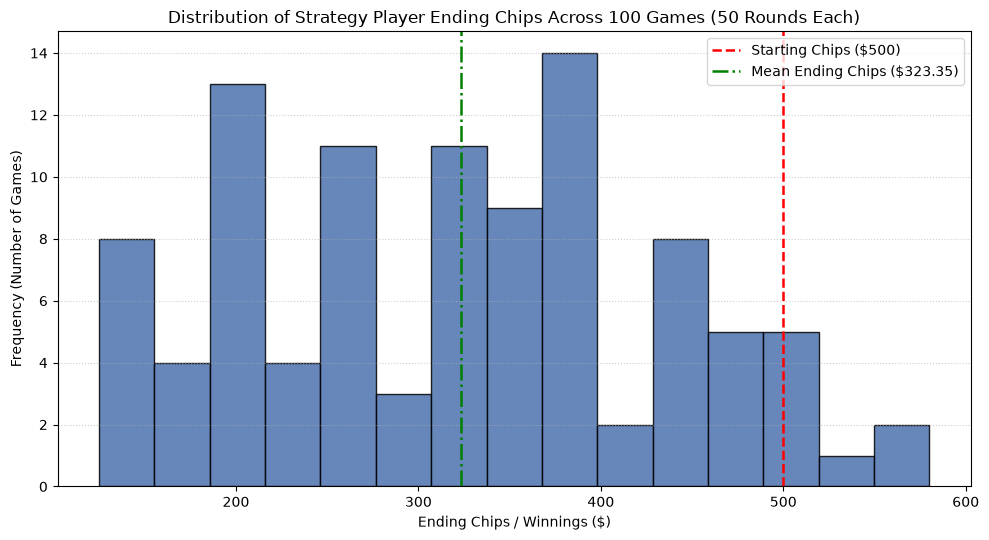

In [21]:
def simulate_single_game(
    starting_chips: float = 500.0,
    bet_size: float = 10.0,
    hit_threshold: int = 0,
    num_decks: int = 4,
    max_rounds: int = 50,
) -> tuple[float, int]:
    strategy_player = CardCountingPlayer(
        name="HiLo_Counter",
        bankroll=starting_chips,
        hit_threshold=hit_threshold,
        base_bet=bet_size,
        verbose=False,
    )
    dealer_bots = [
        DealerStrategyPlayer(name=f"DealerBot_{i}", bankroll=starting_chips, base_bet=bet_size)
        for i in range(1, 4)
    ]

    all_players: List[Player] = [strategy_player] + dealer_bots
    game = Game(players=all_players, num_decks=num_decks, verbose=False)

    rounds_played = 0
    for round_num in range(1, max_rounds + 1):
        if strategy_player.bankroll <= 0:
            break
        game.play_round()
        rounds_played = round_num

    return strategy_player.bankroll, rounds_played


def run_monte_carlo_experiment(
    num_games: int = 100,
    max_rounds: int = 50,
    starting_chips: float = 500.0,
    bet_size: float = 10.0,
    hit_threshold: int = 0,
    num_decks: int = 4,
    seed: int = 42,
) -> List[float]:
    random.seed(seed)

    ending_chips_list: List[float] = []
    net_winnings_per_round_list: List[float] = []

    for _ in range(num_games):
        ending_chips, rounds_played = simulate_single_game(
            starting_chips=starting_chips,
            bet_size=bet_size,
            hit_threshold=hit_threshold,
            num_decks=num_decks,
            max_rounds=max_rounds,
        )
        ending_chips_list.append(ending_chips)

        net_gain = ending_chips - starting_chips
        per_round = net_gain / rounds_played if rounds_played > 0 else 0.0
        net_winnings_per_round_list.append(per_round)

    mean_ending_chips = statistics.mean(ending_chips_list)
    std_ending_chips = statistics.stdev(ending_chips_list) if len(ending_chips_list) > 1 else 0.0

    mean_net_total = statistics.mean([c - starting_chips for c in ending_chips_list])
    avg_winnings_per_round = statistics.mean(net_winnings_per_round_list)

    wins = sum(1 for c in ending_chips_list if c > starting_chips)
    losses = sum(1 for c in ending_chips_list if c < starting_chips)
    ties = sum(1 for c in ending_chips_list if c == starting_chips)

    prob_net_win = wins / num_games
    prob_net_loss = losses / num_games
    prob_break_even = ties / num_games

    print(f"MONTE CARLO RESULTS ({num_games} Games x {max_rounds} Rounds)")
    print(f"Starting Chips                  : ${starting_chips:.2f}")
    print(f"Mean Ending Chips ('Winnings')  : ${mean_ending_chips:.2f}")
    print(f"Standard Deviation (Chips)      : ${std_ending_chips:.2f}")
    print(f"Mean Net Profit/Loss per Game   : ${mean_net_total:+.2f}")
    print(f"Average Net Winnings per Round  : ${avg_winnings_per_round:+.4f} / round")
    print(f"Probability of Net Winning      : {prob_net_win:.2%} ({wins}/{num_games} games)")
    print(f"Probability of Net Losing       : {prob_net_loss:.2%} ({losses}/{num_games} games)")
    print(f"Probability of Breaking Even    : {prob_break_even:.2%} ({ties}/{num_games} games)")

    plt.figure(figsize=(10, 5.5))
    plt.hist(ending_chips_list, bins=15, color="#4C72B0", edgecolor="black", alpha=0.85)
    plt.axvline(starting_chips, color="red", linestyle="--", linewidth=1.8, label=f"Starting Chips (${starting_chips:.0f})")
    plt.axvline(mean_ending_chips, color="green", linestyle="-.", linewidth=1.8, label=f"Mean Ending Chips (${mean_ending_chips:.2f})")

    plt.title(f"Distribution of Strategy Player Ending Chips Across {num_games} Games ({max_rounds} Rounds Each)")
    plt.xlabel("Ending Chips / Winnings ($)")
    plt.ylabel("Frequency (Number of Games)")
    plt.legend()
    plt.grid(axis="y", linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.show()

    return ending_chips_list


if __name__ == "__main__":
    winnings = run_monte_carlo_experiment(
        num_games=100,
        max_rounds=50,
        starting_chips=500.0,
        bet_size=10.0,
        hit_threshold=0,
        num_decks=4,
        seed=42,
    )

9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

THRESHOLD SWEEP SUMMARY (100 Games x 50 Rounds | Start: $500 | Bet: $10)
Threshold |  Mean Chips |   Net P/L |  Avg/Round |  Std Dev |  P(Win) | P(Loss)
       -6 | $    401.50 |    -98.50 |    -1.9700 | $  95.64 |   12.0% |   86.0%
       -4 | $    379.70 |   -120.30 |    -2.4060 | $ 102.07 |    8.0% |   90.0%
       -2 | $    348.80 |   -151.20 |    -3.0240 | $ 110.74 |    8.0% |   92.0%
       +0 | $    323.35 |   -176.65 |    -3.5330 | $ 111.59 |    6.0% |   94.0%
       +2 | $    286.25 |   -213.75 |    -4.2750 | $ 106.15 |    4.0% |   96.0%
       +4 | $    259.40 |   -240.60 |    -4.8120 | $ 102.99 |    2.0% |   98.0%

Optimal Threshold: -6 (Mean Ending Chips: $401.50, Avg/Round: $-1.9700, Win Rate: 12.0%)


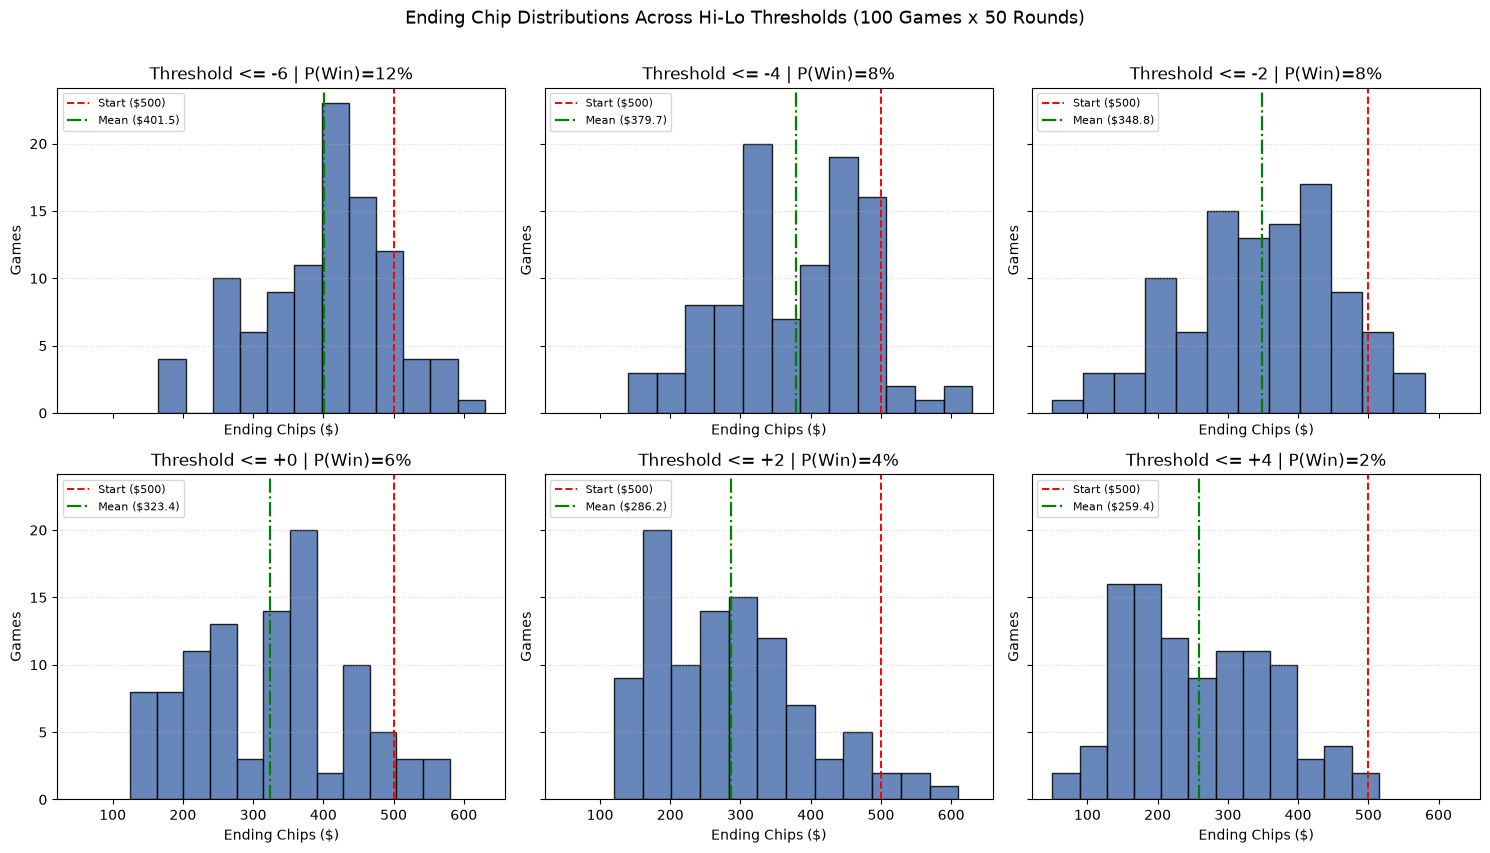

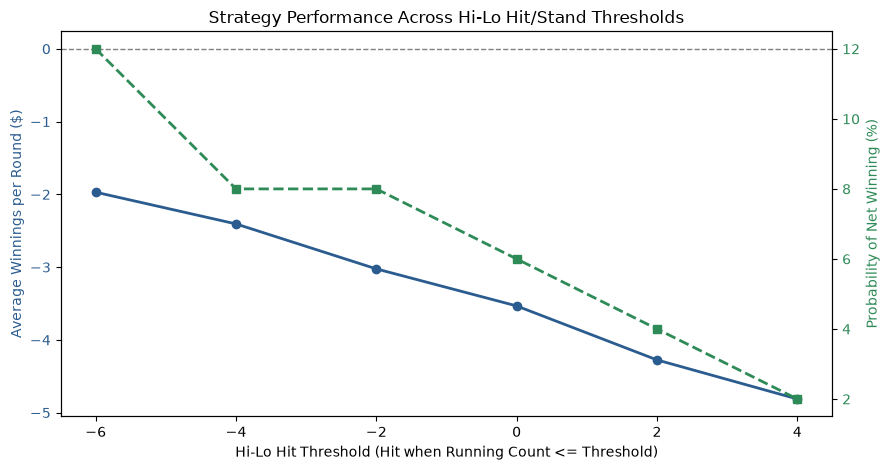

In [24]:
import random
import statistics
from typing import Dict, List


def sweep_thresholds(
    thresholds: List[int],
    num_games: int = 100,
    max_rounds: int = 50,
    starting_chips: float = 500.0,
    bet_size: float = 10.0,
    num_decks: int = 4,
    base_seed: int = 42,
) -> List[Dict]:
    results: List[Dict] = []

    for thresh in thresholds:
        # Reset seed for each threshold so all thresholds face the exact same shoe sequences
        random.seed(base_seed)

        ending_chips_list: List[float] = []
        per_round_list: List[float] = []

        for _ in range(num_games):
            ending_chips, rounds_played = simulate_single_game(
                starting_chips=starting_chips,
                bet_size=bet_size,
                hit_threshold=thresh,
                num_decks=num_decks,
                max_rounds=max_rounds,
            )
            ending_chips_list.append(ending_chips)
            net_gain = ending_chips - starting_chips
            per_round_list.append(net_gain / rounds_played if rounds_played > 0 else 0.0)

        mean_chips = statistics.mean(ending_chips_list)
        std_chips = statistics.stdev(ending_chips_list)
        avg_per_round = statistics.mean(per_round_list)

        wins = sum(1 for c in ending_chips_list if c > starting_chips)
        losses = sum(1 for c in ending_chips_list if c < starting_chips)
        ties = sum(1 for c in ending_chips_list if c == starting_chips)

        results.append({
            "threshold": thresh,
            "ending_chips": ending_chips_list,
            "mean_chips": mean_chips,
            "std_chips": std_chips,
            "mean_net": mean_chips - starting_chips,
            "avg_per_round": avg_per_round,
            "prob_win": wins / num_games,
            "prob_loss": losses / num_games,
            "prob_tie": ties / num_games,
        })

    print(f"THRESHOLD SWEEP SUMMARY ({num_games} Games x {max_rounds} Rounds | Start: ${starting_chips:.0f} | Bet: ${bet_size:.0f})")
    print(
        f"{'Threshold':>9} | {'Mean Chips':>11} | {'Net P/L':>9} | {'Avg/Round':>10} | "
        f"{'Std Dev':>8} | {'P(Win)':>7} | {'P(Loss)':>7}"
    )

    for r in results:
        print(
            f"{r['threshold']:>+9d} | "
            f"${r['mean_chips']:>10.2f} | "
            f"{r['mean_net']:>+9.2f} | "
            f"{r['avg_per_round']:>+10.4f} | "
            f"${r['std_chips']:>7.2f} | "
            f"{r['prob_win']*100:>6.1f}% | "
            f"{r['prob_loss']*100:>6.1f}%"
        )

    # Identify optimal threshold by highest Mean Ending Chips / Avg Winnings per Round
    best = max(results, key=lambda x: x["mean_chips"])
    print(
        f"\nOptimal Threshold: {best['threshold']:+d} "
        f"(Mean Ending Chips: ${best['mean_chips']:.2f}, "
        f"Avg/Round: ${best['avg_per_round']:+.4f}, "
        f"Win Rate: {best['prob_win']*100:.1f}%)"
    )

    # --- Plot 1: Subplots of Histograms for Each Threshold ---
    cols = 3
    rows = (len(results) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 4.2 * rows), sharex=True, sharey=True)
    axes = axes.flatten()

    for idx, r in enumerate(results):
        ax = axes[idx]
        ax.hist(r["ending_chips"], bins=12, color="#4C72B0", edgecolor="black", alpha=0.85)
        ax.axvline(starting_chips, color="red", linestyle="--", linewidth=1.4, label="Start ($500)")
        ax.axvline(r["mean_chips"], color="green", linestyle="-.", linewidth=1.6, label=f"Mean (${r['mean_chips']:.1f})")
        ax.set_title(f"Threshold <= {r['threshold']:+d} | P(Win)={r['prob_win']*100:.0f}%")
        ax.set_xlabel("Ending Chips ($)")
        ax.set_ylabel("Games")
        ax.legend(fontsize=8)
        ax.grid(axis="y", linestyle=":", alpha=0.5)

    for j in range(len(results), len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle("Ending Chip Distributions Across Hi-Lo Thresholds (100 Games x 50 Rounds)", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()

    # --- Plot 2: Mean Winnings per Round & Win Probability vs. Threshold ---
    fig, ax1 = plt.subplots(figsize=(9, 4.8))
    thresh_vals = [r["threshold"] for r in results]
    avg_round_vals = [r["avg_per_round"] for r in results]
    win_probs = [r["prob_win"] * 100 for r in results]

    color1 = "#2b5c8f"
    ax1.set_xlabel("Hi-Lo Hit Threshold (Hit when Running Count <= Threshold)")
    ax1.set_ylabel("Average Winnings per Round ($)", color=color1)
    ax1.plot(thresh_vals, avg_round_vals, marker="o", linewidth=2, color=color1, label="Avg Winnings / Round ($)")
    ax1.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax1.tick_params(axis="y", labelcolor=color1)
    ax1.set_xticks(thresh_vals)

    ax2 = ax1.twinx()
    color2 = "#2e8b57"
    ax2.set_ylabel("Probability of Net Winning (%)", color=color2)
    ax2.plot(thresh_vals, win_probs, marker="s", linestyle="--", linewidth=2, color=color2, label="P(Net Win) %")
    ax2.tick_params(axis="y", labelcolor=color2)

    plt.title("Strategy Performance Across Hi-Lo Hit/Stand Thresholds")
    fig.tight_layout()
    plt.show()

    return results


if __name__ == "__main__":
    tested_thresholds = [-6, -4, -2, 0, 2, 4]
    sweep_results = sweep_thresholds(
        thresholds=tested_thresholds,
        num_games=100,
        max_rounds=50,
        starting_chips=500.0,
        bet_size=10.0,
        num_decks=4,
        base_seed=42,
    )

10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

STRATEGY COMPARISON (100 Games x 50 Rounds | Start: $500 | Base Bet: $10)
Strategy                                 | Mean Chips |   Net P/L |  Avg/Rnd |  Std Dev |  P(Win)
1. Old Strategy (Hi-Lo Thresh -4, Flat)  | $   379.70 |   -120.30 |  -2.4060 | $ 102.07 |    8.0%
2. New Strategy (Basic + TC Spread)      | $   509.70 |     +9.70 |  +0.1940 | $ 132.38 |   48.0%
3. Dealer Mimic (Hit < 17, Flat)         | $   471.75 |    -28.25 |  -0.5650 | $  71.81 |   32.0%


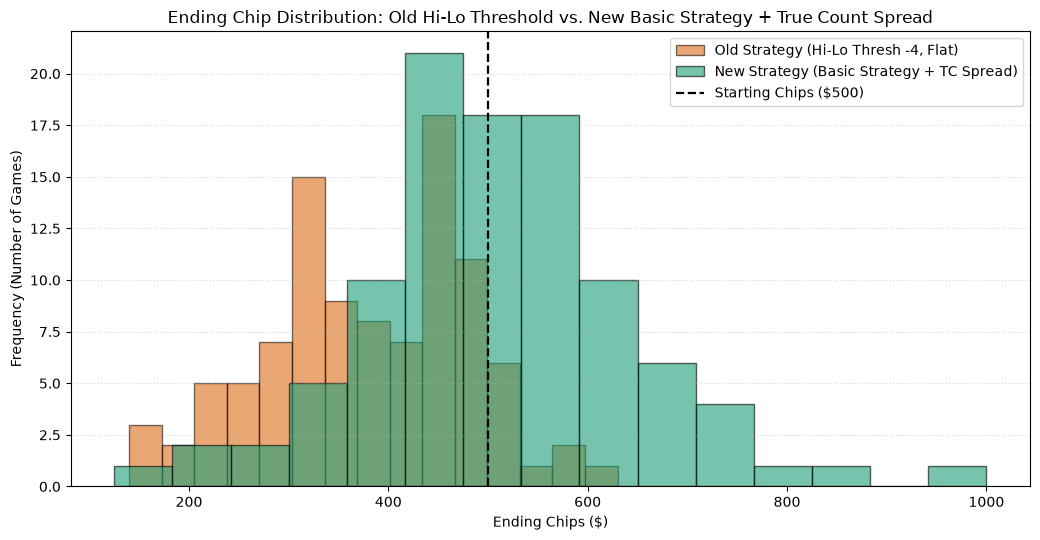

In [27]:
import random
import statistics
from typing import Dict, List, Optional
import matplotlib.pyplot as plt

class BasicStrategyCounterPlayer(CardCountingPlayer):
    def __init__(
        self,
        name: str,
        bankroll: float = 500.0,
        base_bet: float = 10.0,
        max_spread: int = 4,
        verbose: bool = False,
    ) -> None:
        super().__init__(
            name=name,
            bankroll=bankroll,
            hit_threshold=0,
            base_bet=base_bet,
            verbose=verbose,
        )
        self.max_spread: int = max_spread
        self.dealer_upcard: Optional[Card] = None
        self.remaining_cards: int = 52

    def update_table_state(self, dealer_upcard: Optional[Card], remaining_cards: int) -> None:
        self.dealer_upcard = dealer_upcard
        self.remaining_cards = max(1, remaining_cards)

    def get_true_count(self) -> float:
        remaining_decks = max(0.5, self.remaining_cards / 52.0)
        return self.running_count / remaining_decks

    def choose_bet(self) -> float:
        true_count = self.get_true_count()
        if true_count >= 4.0:
            multiplier = self.max_spread
        elif true_count >= 3.0:
            multiplier = min(3, self.max_spread)
        elif true_count >= 2.0:
            multiplier = min(2, self.max_spread)
        else:
            multiplier = 1

        desired_bet = self.base_bet * multiplier
        return min(desired_bet, self.bankroll)

    def _is_soft_hand(self) -> bool:
        raw_sum = sum(c.get_value() for c in self.hand.cards)
        aces = sum(1 for c in self.hand.cards if c.rank == "Ace")
        while raw_sum > 21 and aces > 0:
            raw_sum -= 10
            aces -= 1
        return aces > 0

    def decide_action(self) -> str:
        total = self.hand.calculate_value()
        if total <= 11:
            return "hit"
        if total >= 21:
            return "stand"

        up_val = self.dealer_upcard.get_value() if self.dealer_upcard else 10
        is_soft = self._is_soft_hand()

        if is_soft:
            if total <= 17:
                return "hit"
            if total == 18:
                return "stand" if up_val in (2, 3, 4, 5, 6, 7, 8) else "hit"
            return "stand"

        if total >= 17:
            return "stand"
        if total == 12:
            return "stand" if up_val in (4, 5, 6) else "hit"
        # Totals 13 through 16
        return "stand" if up_val in (2, 3, 4, 5, 6) else "hit"


class EnhancedGame(Game):
    def play_round(self) -> None:
        self.dealer.reset_hand()
        for player in self.players:
            player.reset_hand()
            if isinstance(player, BasicStrategyCounterPlayer):
                player.update_table_state(dealer_upcard=None, remaining_cards=len(self.deck))

        for player in self.players:
            if player.bankroll <= 0:
                continue
            if hasattr(player, "choose_bet"):
                player.place_bet(player.choose_bet())

        self.deal_initial_hands()
        upcard = self.dealer.show_upcard()
        for player in self.players:
            if isinstance(player, BasicStrategyCounterPlayer):
                player.update_table_state(dealer_upcard=upcard, remaining_cards=len(self.deck))

        if self.dealer.hand.is_blackjack():
            if len(self.dealer.hand.cards) >= 2:
                self._notify_card_seen(self.dealer.hand.cards[1])
        else:
            for player in self.players:
                if player.hand.bet > 0:
                    self.play_player_turn(player)
            self.play_dealer_turn()

        self.resolve_round()


def compare_strategies(
    num_games: int = 100,
    max_rounds: int = 50,
    starting_chips: float = 500.0,
    base_bet: float = 10.0,
    num_decks: int = 4,
    base_seed: int = 42,
) -> Dict[str, List[float]]:
    strategies = {
        "1. Old Strategy (Hi-Lo Thresh -4, Flat)": lambda: CardCountingPlayer(
            name="Old_HiLo", bankroll=starting_chips, hit_threshold=-4, base_bet=base_bet, verbose=False
        ),
        "2. New Strategy (Basic + TC Spread)": lambda: BasicStrategyCounterPlayer(
            name="Basic_TC_Spread", bankroll=starting_chips, base_bet=base_bet, max_spread=4, verbose=False
        ),
        "3. Dealer Mimic (Hit < 17, Flat)": lambda: DealerStrategyPlayer(
            name="Dealer_Mimic", bankroll=starting_chips, base_bet=base_bet
        ),
    }

    all_distributions: Dict[str, List[float]] = {}

    print(f"STRATEGY COMPARISON ({num_games} Games x {max_rounds} Rounds | Start: ${starting_chips:.0f} | Base Bet: ${base_bet:.0f})")
    print(
        f"{'Strategy':<40} | {'Mean Chips':>10} | {'Net P/L':>9} | {'Avg/Rnd':>8} | "
        f"{'Std Dev':>8} | {'P(Win)':>7}"
    )

    for label, player_factory in strategies.items():
        random.seed(base_seed)  # Identical card shoes across all 3 strategies
        ending_chips_list: List[float] = []
        per_round_list: List[float] = []

        for _ in range(num_games):
            hero = player_factory()
            opponents = [
                DealerStrategyPlayer(name=f"Bot_{i}", bankroll=starting_chips, base_bet=base_bet)
                for i in range(1, 4)
            ]
            game = EnhancedGame(players=[hero] + opponents, num_decks=num_decks, verbose=False)

            rounds_played = 0
            for r in range(1, max_rounds + 1):
                if hero.bankroll <= 0:
                    break
                game.play_round()
                rounds_played = r

            ending_chips_list.append(hero.bankroll)
            net = hero.bankroll - starting_chips
            per_round_list.append(net / rounds_played if rounds_played > 0 else 0.0)

        all_distributions[label] = ending_chips_list
        mean_c = statistics.mean(ending_chips_list)
        std_c = statistics.stdev(ending_chips_list)
        avg_r = statistics.mean(per_round_list)
        p_win = sum(1 for c in ending_chips_list if c > starting_chips) / num_games

        print(
            f"{label:<40} | ${mean_c:>9.2f} | {mean_c - starting_chips:>+9.2f} | "
            f"{avg_r:>+8.4f} | ${std_c:>7.2f} | {p_win*100:>6.1f}%"
        )

    plt.figure(figsize=(10.5, 5.5))
    plt.hist(
        all_distributions["1. Old Strategy (Hi-Lo Thresh -4, Flat)"],
        bins=15,
        alpha=0.55,
        color="#d95f02",
        edgecolor="black",
        label="Old Strategy (Hi-Lo Thresh -4, Flat)",
    )
    plt.hist(
        all_distributions["2. New Strategy (Basic + TC Spread)"],
        bins=15,
        alpha=0.60,
        color="#1b9e77",
        edgecolor="black",
        label="New Strategy (Basic Strategy + TC Spread)",
    )
    plt.axvline(starting_chips, color="black", linestyle="--", linewidth=1.6, label=f"Starting Chips (${starting_chips:.0f})")
    plt.title("Ending Chip Distribution: Old Hi-Lo Threshold vs. New Basic Strategy + True Count Spread")
    plt.xlabel("Ending Chips ($)")
    plt.ylabel("Frequency (Number of Games)")
    plt.legend()
    plt.grid(axis="y", linestyle=":", alpha=0.5)
    plt.tight_layout()
    plt.show()

    return all_distributions


if __name__ == "__main__":
    compare_strategies(num_games=100, max_rounds=50, starting_chips=500.0, base_bet=10.0, num_decks=4, base_seed=42)